# Homework 6

The goal of this homework is to consider the bias-variance decomposition for three different models: 
* a linear regression model;
* a moderately complex neural network model;
* and a more complex neural network model.

These models will all be attempting to model a sine curve with some added random noise.

## Question

Here we will define the underlying data, which will follow sine curve plus some random noise.

* Instantiate a NumPy random number generator `rng` with a seed for reproducibility.  If you want to match the most intuitive values, use seed 210.  When I tried some other seeds, the results at the end were less intuitive.
* Define `x` to be a NumPy array of 250 linearly spaced points between 0 and 10.
* Use `rng.shuffle(x)` to mix up the order of the values in `x`.  Note that this function shuffles `x` *in place*, so you do not want to use `x = rng.shuffle(x)`, instead just use `rng.shuffle(x)`.
* Let $\epsilon$ denote a length 250 NumPy array of independent normally distributed noise values with mean 0 and standard deviation 0.3 (use `rng.normal`).  Define `y` to be $\sin(x) + \epsilon$.
* Plot a scatterplot of x vs y.  It should roughly (but not perfectly) follow a sine curve.

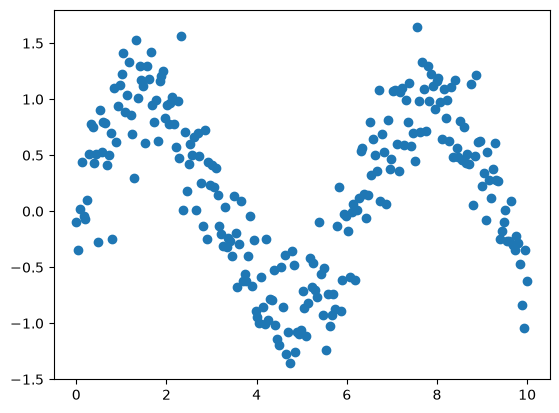

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(210)

x = np.linspace(0, 10, 250)
rng.shuffle(x)

epsilon = rng.normal(0, 0.3, 250)
y = np.sin(x) + epsilon

fig, ax = plt.subplots()
ax.scatter(x, y)

## Question

Here we will make 10 different training datasets.

* Define `x2` and `y2` (2 for "2-dimensional") to be versions of `x` and `y` reshaped into size $10 \times 25$.  We are going to think of these 10 rows as 10 different training datasets.
* Check your answer by drawing another scatterplot, using just the top row of `x2` and of `y2`.  It should look similar to your previous scatterplot, but with only 25 points instead of 250.

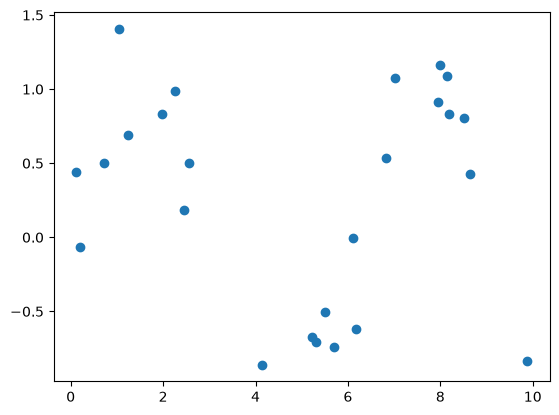

In [3]:
x2 = x.reshape((10, 25))
y2 = y.reshape((10, 25))

fig, ax = plt.subplots()
ax.scatter(x2[0], y2[0])

## Question

Here we define the models.

* Define `model_a` to be a LinearRegression model.  No input arguments are necessary when instantiating it.

* Use the following definitions for our two neural network models.  Assign `model_b` two hidden layers with 16 nodes each, and assign `model_c` two hidden layers with 128 nodes each.

```
model_b = MLPRegressor(
    hidden_layer_sizes=(16, 16),
    activation="relu",
    solver="lbfgs",
    alpha=0,
    max_iter=2500,
    tol=1e-6,
    random_state=15,
)

model_c = MLPRegressor(
    hidden_layer_sizes=(128, 128),
    activation="relu",
    solver="lbfgs",
    alpha=0,
    max_iter=2500,
    tol=1e-6,
    random_state=15,
)
```

* Put the three models into a length 3 list and assign it to the variable name `models`.

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

model_a = LinearRegression()

model_b = MLPRegressor(
    hidden_layer_sizes=(16, 16),
    activation="relu",
    solver="lbfgs",
    alpha=0,
    max_iter=2500,
    tol=1e-6,
    random_state=15,
)

model_c = MLPRegressor(
    hidden_layer_sizes=(128, 128),
    activation="relu",
    solver="lbfgs",
    alpha=0,
    max_iter=2500,
    tol=1e-6,
    random_state=15,
)

models = [model_a, model_b, model_c]

## Question

* Define `x_star` to be `7`.
* Using `np.empty`, create a $10 \times 3$ NumPy array.  Name your array `results_arr`.
* For each of our three models, for each of our 10 training datasets (i.e., the 10 rows of `x2` and `y2`), fit the model using the given training dataset.  (It's fine to use `for i in range(3):` for iterating through the models.  A more sophisticated approach is to use `for i, model in enumerate(models):`.)
* Using the fit model, evaluate at `x_star`.  Record your answer in `results_arr`.  (The columns of `results_arr` correspond to the models; the rows correspond to the training datasets.  Hint.  The output of `model.predict` will be a length 1 NumPy array.  To get a number out of that, you can use `.item()`.)

In [ ]:
x_star = 7

results_arr = np.empty((10, 3))

for i, model in enumerate(models):
    for j in range(10):
        model.fit(x2[j].reshape(-1, 1), y2[j])
        results_arr[j, i] = model.predict([[x_star]]).item()

## Question

* How many parameters are learned after fitting each of these models?  Don't forget the intercept.  (Hint.  If `arr` is a NumPy array, then `arr.size` will be the number of entries in it.)

In [ ]:
model_a.coef_.size + np.size(model_a.intercept_)

2

In [7]:
sum(c.size for c in model_b.coefs_) + sum(b.size for b in model_b.intercepts_)

321

In [8]:
sum(c.size for c in model_c.coefs_) + sum(b.size for b in model_c.intercepts_)

16897

## Question

Recall from AI SCI 220A that the expected test Mean Squared Error at a specific input $x_*$ is

$$
\mathbb E_{D,\epsilon_*}
\left[\left(Y_*-\widehat f_D(x_*)\right)^2\right]
=\operatorname{Bias}(x_*)^2
+\operatorname{Var}_D\!\left(\widehat f_D(x_*)\right)
+\sigma^2.
$$

Here $D$ denotes a training dataset, and $\widehat f_D$ is the model fitted to that dataset. The true mean function is $f(x)=\sin(x)$. At the fixed input $x_*=7$, a new response is $Y_*=f(x_*)+\epsilon_*$, where $\epsilon_*$ is new noise, independent of the training data, with mean 0 and standard deviation 0.3. Here $\sigma^2$ denotes the variance of the random noise.  Apply the formula separately to each model, averaging predictions over the different training datasets.


* What is the true mean value $f(x_*)$?
* Estimate the squared bias of each of the three models, using the data in `results_arr` (so your bias should involve an average over the 10 predictions).
* Estimate the variance of each of the three models, using the data in `results_arr`.
* Estimate the expected test error of each of the three models, using the above formula.

In [9]:
f_star = np.sin(x_star)
f_star

np.float64(0.6569865987187891)

In [ ]:
bias_sq = (results_arr.mean(axis=0) - f_star) ** 2
bias_sq

array([0.22979162, 0.01013976, 0.00375701])

In [ ]:
variance = results_arr.var(axis=0)
variance

array([0.01556902, 0.03089781, 0.02768275])

In [ ]:
sigma2 = 0.3 ** 2

test_error = bias_sq + variance + sigma2
test_error

array([0.33536064, 0.13103757, 0.12143976])

## Question

* In a markdown cell, sort the three models from lowest estimated square bias to highest estimated square bias.  Does it match your expectation?  (Not necessarily, don't worry if it seems counterintuitive.  It depends a lot on the particular data.)
* In a markdown cell, sort the three models from lowest variance to highest variance.  (Again, not necessarily.)

Bias (lowest to highest): model_c -> model_b -> model_a. The straight-line model (model_a) has the most bias because it can't bend to follow the sine curve, so its predictions stay far from the true value. The two neural nets are flexible enough to follow the curve, so they land close on average.

Variance (lowest to highest): model_a -> model_c -> model_b. The simple linear model barely changes from one training set to the next (only 2 parameters), so it has the lowest variance. The surprise is that the bigger network (model_c) had slightly lower variance than the smaller one (model_b) — but they're very close, and with only 10 training sets this is probably just luck of the data.

## Submission

* When you've completed this assignment, save your work, commit and push your changes to GitHub, and share the GitHub directory through Gradescope, linked from the left side of Canvas.